<a href="https://colab.research.google.com/github/Murcha1990/HSE_FitPredict_AI_School/blob/main/ML/18_11/03_practice_ames_solution.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Решение практики: Ames House Prices

Ноутбук для преподавателя. Структура:

1. Проблемы с качеством данных
2. **Подсказки по feature engineering** — показать студентам после первых 20 минут практики
3. Модели sklearn: от базового решения к хорошему
4. CatBoost
5. Итоговая таблица и выводы

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import root_mean_squared_error

RANDOM_STATE = 42
plt.rcParams['figure.figsize'] = (9, 4)

In [ ]:
ames = fetch_openml(name='house_prices', as_frame=True, parser='auto')
df = ames.frame.drop(columns='Id')
print(df.shape)
df.head()

(1460, 80)


,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [ ]:
X = df.drop(columns='SalePrice')
y = df['SalePrice']

# Разбиение фиксировано: у всех одинаковый test, поэтому результаты можно сравнивать
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE)

num_cols = X.select_dtypes(include='number').columns.tolist()
cat_cols = X.select_dtypes(exclude='number').columns.tolist()
print(f'train: {X_train.shape}, test: {X_test.shape}')
print(f'числовых признаков: {len(num_cols)}, категориальных: {len(cat_cols)}')

train: (1095, 79), test: (365, 79)
числовых признаков: 36, категориальных: 43


In [ ]:
def score(y_true, y_pred):
    """RMSE в логарифмах цены — метрика соревнования Kaggle House Prices.
    Ошибка 0.10 примерно означает «ошибаемся в среднем на 10%»."""
    y_pred = np.maximum(y_pred, 1)
    return root_mean_squared_error(np.log1p(y_true), np.log1p(y_pred))

# 1. Проблемы с качеством данных

### 1.1. Пропуски: часто это не «неизвестно», а «нет объекта»

,0
PoolQC,0.995
MiscFeature,0.961
Alley,0.936
Fence,0.801
FireplaceQu,0.468
LotFrontage,0.183
GarageYrBlt,0.053
GarageQual,0.053
GarageFinish,0.053
GarageType,0.053


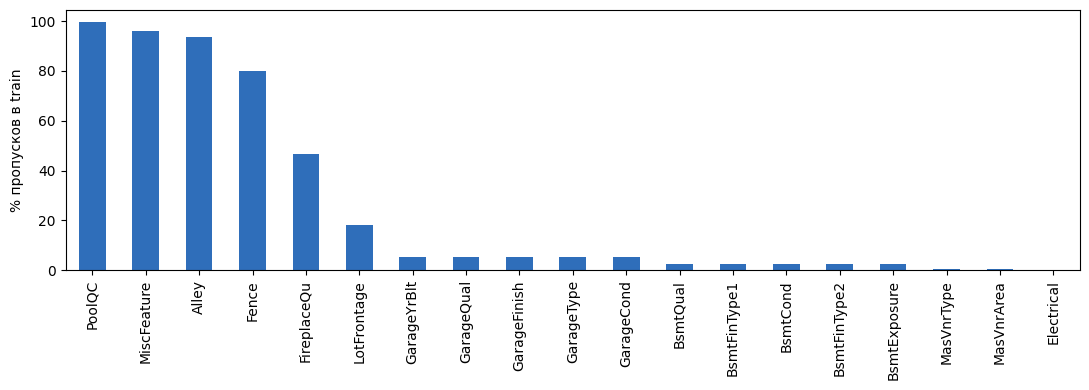

In [ ]:
missing = X_train.isna().mean().sort_values(ascending=False)
missing = missing[missing > 0]
ax = (100 * missing).plot.bar(color='#2F6EBA', figsize=(11, 4))
ax.set_ylabel('% пропусков в train')
plt.tight_layout()
missing.round(3).head(20)

По описанию датасета большинство пропусков **означают отсутствие объекта**:

- `PoolQC` — нет бассейна, `MiscFeature` — нет доп. построек, `Alley` — нет переулка, `Fence` — нет забора;
- `FireplaceQu` — нет камина;
- `Garage*` — нет гаража, `Bsmt*` — нет подвала, `MasVnrType` — нет облицовки.

Их правильно заполнять значением `'None'` (для категорий) или `0` (для площадей и количеств), а не медианой.

Настоящие пропуски — это, например, `LotFrontage` (длина участка вдоль улицы): её разумно заполнить медианой по району.

In [ ]:
# Проверка: где нет гаража, там пусто во всех гаражных признаках
garage_cols = ['GarageType', 'GarageFinish', 'GarageQual', 'GarageCond', 'GarageYrBlt']
print(X_train[garage_cols].isna().sum())
print('GarageArea у домов без GarageType:', X_train.loc[X_train['GarageType'].isna(), 'GarageArea'].unique()[:5])

GarageType      58
GarageFinish    58
GarageQual      58
GarageCond      58
GarageYrBlt     58
dtype: int64
GarageArea у домов без GarageType: [0]


### 1.2. Целевая переменная сильно скошена

Асимметрия: до 1.76 , после логарифма 0.12


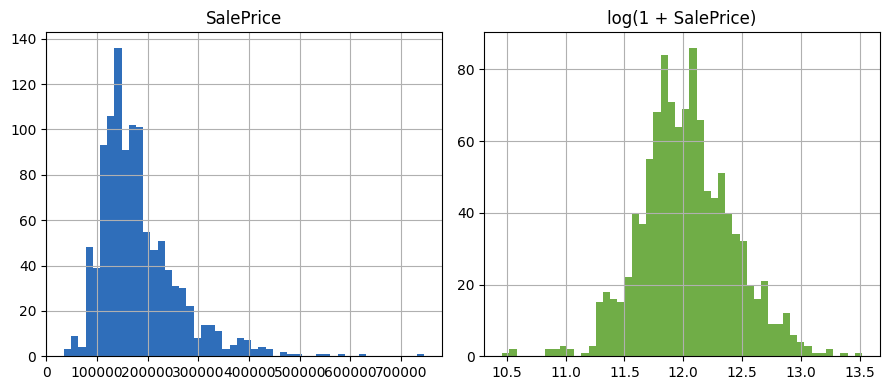

In [ ]:
fig, axes = plt.subplots(1, 2)
y_train.hist(bins=50, ax=axes[0], color='#2F6EBA')
axes[0].set_title('SalePrice')
np.log1p(y_train).hist(bins=50, ax=axes[1], color='#70AD47')
axes[1].set_title('log(1 + SalePrice)')
plt.tight_layout()
print('Асимметрия: до', round(y_train.skew(), 2), ', после логарифма', round(np.log1p(y_train).skew(), 2))

Метрика считается в логарифмах, поэтому выгоднее **обучать модель на `log(1 + SalePrice)`** и потом возвращаться к цене.

### 1.3. Выбросы

Выбросов в train: 2


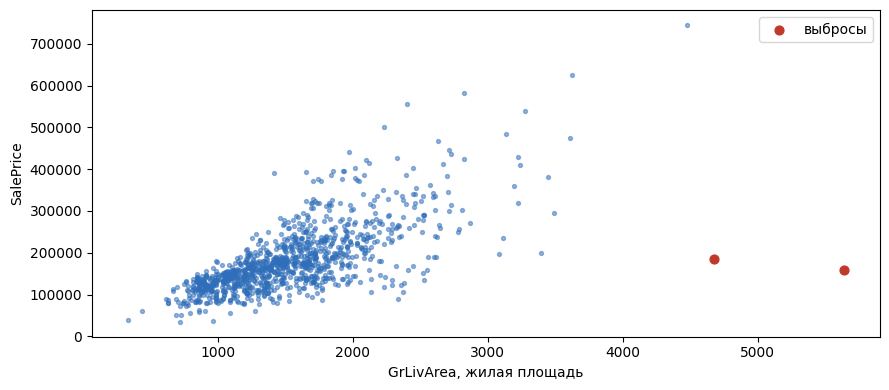

In [ ]:
plt.scatter(X_train['GrLivArea'], y_train, s=8, alpha=0.5, color='#2F6EBA')
out = (X_train['GrLivArea'] > 4000) & (y_train < 300000)
plt.scatter(X_train.loc[out, 'GrLivArea'], y_train[out], s=40, color='#C0392B', label='выбросы')
plt.xlabel('GrLivArea, жилая площадь'); plt.ylabel('SalePrice'); plt.legend()
plt.tight_layout()
print('Выбросов в train:', out.sum())

Огромные дома по бросовой цене — известная аномалия датасета (это частичные продажи). Их стоит **убрать из train**, из test ничего не удаляем.

### 1.4. Типы признаков обманчивы

In [ ]:
qual_cols = ['ExterQual', 'ExterCond', 'BsmtQual', 'BsmtCond', 'HeatingQC',
             'KitchenQual', 'FireplaceQu', 'GarageQual', 'GarageCond', 'PoolQC']
print(X_train['KitchenQual'].value_counts(dropna=False))
print()
print('MSSubClass — это код типа дома, а не число:', sorted(X_train['MSSubClass'].unique().tolist())[:10])
print()
print('Почти константные признаки:')
for c in cat_cols:
    top = X_train[c].value_counts(normalize=True, dropna=False).iloc[0]
    if top > 0.98:
        print(f'  {c}: {top:.1%} объектов в одной категории')

KitchenQual
TA    550
Gd    440
Ex     73
Fa     32
Name: count, dtype: int64

MSSubClass — это код типа дома, а не число: [20, 30, 40, 45, 50, 60, 70, 75, 80, 85]

Почти константные признаки:
  Street: 99.6% объектов в одной категории
  Utilities: 99.9% объектов в одной категории
  Condition2: 99.2% объектов в одной категории
  RoofMatl: 98.3% объектов в одной категории
  PoolQC: 99.5% объектов в одной категории


- Оценки качества (`Ex`, `Gd`, `TA`, `Fa`, `Po`) хранятся строками, но это **упорядоченная шкала** — её лучше перевести в числа 5…1.
- `MSSubClass` записан числом, но это **категория** (код типа постройки).
- Есть почти константные признаки (`Utilities`, `Street`), они ничего не дают.
- Много редких категорий: при one-hot они превращаются в почти пустые столбцы.

**Как это поможет моделям.** Логарифм выравнивает вклад дешёвых и дорогих домов. Правильно заполненные пропуски несут смысл («нет гаража»), а не шум. Числовые оценки качества позволяют дереву делать разбиения вида «качество кухни ≥ хорошее». Удаление выбросов не даёт деревьям строить листья под аномалии. Суммарные признаки (общая площадь, число ванных) деревья сами собрать не могут: каждое разбиение смотрит только на один признак.

# 2. Подсказки по feature engineering

*Показать студентам после первых 20 минут практики.*

1. **Прологарифмируйте целевую переменную**: обучайте на `log1p(SalePrice)`, предсказание возвращайте через `expm1`. Удобно сделать через `TransformedTargetRegressor`.
2. **Заполните пропуски по смыслу**: «нет объекта» → `'None'` или `0`; `LotFrontage` → медиана по району (`Neighborhood`); `GarageYrBlt` → год постройки дома.
3. **Переведите оценки качества в числа**: `Ex=5, Gd=4, TA=3, Fa=2, Po=1, None=0`. Так же можно поступить с `BsmtExposure`, `BsmtFinType1/2`, `GarageFinish`.
4. **Сделайте `MSSubClass` категориальным**, уберите почти константные признаки (`Utilities`).
5. **Добавьте суммарные признаки**:
   - `TotalSF` = площадь подвала + 1-го + 2-го этажа;
   - `TotalBath` = полные ванные + 0,5 × неполные (включая подвал);
   - `TotalPorchSF` = сумма площадей всех веранд и террас;
   - `HouseAge` = год продажи − год постройки, `RemodAge` = год продажи − год ремонта;
   - флаги `HasGarage`, `HasPool`, `HasFireplace`, `Has2ndFloor`;
   - `QualArea` = `OverallQual × GrLivArea`.
6. **Уберите из train выбросы**: `GrLivArea > 4000` при цене ниже $300 000.
7. **Для деревьев хватит `OrdinalEncoder`**: one-hot на 40+ категориальных признаках раздувает таблицу и обычно не помогает деревьям.

# 3. Модели sklearn

### 3.1. Предобработка и новые признаки

In [ ]:
NONE_CAT = ['Alley', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2',
            'FireplaceQu', 'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond',
            'PoolQC', 'Fence', 'MiscFeature', 'MasVnrType']
ZERO_NUM = ['MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF',
            'BsmtFullBath', 'BsmtHalfBath', 'GarageCars', 'GarageArea']
QUAL_MAP = {'Ex': 5, 'Gd': 4, 'TA': 3, 'Fa': 2, 'Po': 1, 'None': 0}
ORD_MAPS = {
    'BsmtExposure': {'Gd': 4, 'Av': 3, 'Mn': 2, 'No': 1, 'None': 0},
    'BsmtFinType1': {'GLQ': 6, 'ALQ': 5, 'BLQ': 4, 'Rec': 3, 'LwQ': 2, 'Unf': 1, 'None': 0},
    'BsmtFinType2': {'GLQ': 6, 'ALQ': 5, 'BLQ': 4, 'Rec': 3, 'LwQ': 2, 'Unf': 1, 'None': 0},
    'GarageFinish': {'Fin': 3, 'RFn': 2, 'Unf': 1, 'None': 0},
}


class Cleaner:
    """Заполнение пропусков по смыслу и новые признаки.
    Статистики (медианы, моды) считаются только по train в fit."""

    def fit(self, X):
        X = X.copy()
        self.lot_by_nbhd = X.groupby('Neighborhood', observed=True)['LotFrontage'].median()
        self.lot_median = X['LotFrontage'].median()
        self.modes = {c: X[c].mode().iloc[0] for c in X.columns if not pd.api.types.is_numeric_dtype(X[c])}
        return self

    def transform(self, X):
        X = X.copy()
        cats = [c for c in X.columns if not pd.api.types.is_numeric_dtype(X[c])]
        X[cats] = X[cats].astype(object)

        # 1. Пропуски по смыслу
        for c in NONE_CAT:
            X[c] = X[c].fillna('None')
        for c in ZERO_NUM:
            X[c] = X[c].fillna(0)
        X['GarageYrBlt'] = X['GarageYrBlt'].fillna(X['YearBuilt'])
        nb = X['Neighborhood'].astype(object).map(self.lot_by_nbhd).astype(float)
        X['LotFrontage'] = X['LotFrontage'].fillna(nb).fillna(self.lot_median)
        for c in cats:
            X[c] = X[c].fillna(self.modes.get(c, 'Missing'))

        # 2. Порядковые признаки → числа
        for c in qual_cols:
            X[c] = X[c].map(QUAL_MAP).fillna(0)
        for c, m in ORD_MAPS.items():
            X[c] = X[c].map(m).fillna(0)

        # 3. Код типа дома — категория, почти константный признак — убираем
        X['MSSubClass'] = X['MSSubClass'].astype(int).astype(str)
        X = X.drop(columns=['Utilities'])

        # 4. Новые признаки
        X['TotalSF'] = X['TotalBsmtSF'] + X['1stFlrSF'] + X['2ndFlrSF']
        X['TotalBath'] = (X['FullBath'] + 0.5 * X['HalfBath']
                          + X['BsmtFullBath'] + 0.5 * X['BsmtHalfBath'])
        X['TotalPorchSF'] = (X['OpenPorchSF'] + X['EnclosedPorch'] + X['3SsnPorch']
                             + X['ScreenPorch'] + X['WoodDeckSF'])
        X['HouseAge'] = X['YrSold'] - X['YearBuilt']
        X['RemodAge'] = X['YrSold'] - X['YearRemodAdd']
        X['IsRemodeled'] = (X['YearRemodAdd'] != X['YearBuilt']).astype(int)
        X['HasGarage'] = (X['GarageArea'] > 0).astype(int)
        X['HasPool'] = (X['PoolArea'] > 0).astype(int)
        X['HasFireplace'] = (X['Fireplaces'] > 0).astype(int)
        X['Has2ndFloor'] = (X['2ndFlrSF'] > 0).astype(int)
        X['QualArea'] = X['OverallQual'] * X['GrLivArea']
        return X


# Убираем выбросы только из train
keep = ~((X_train['GrLivArea'] > 4000) & (y_train < 300000))
X_train_clean, y_train_clean = X_train[keep], y_train[keep]

cleaner = Cleaner().fit(X_train_clean)
X_train_fe = cleaner.transform(X_train_clean)
X_test_fe = cleaner.transform(X_test)

num_fe = X_train_fe.select_dtypes(include='number').columns.tolist()
cat_fe = X_train_fe.select_dtypes(exclude='number').columns.tolist()
print('Признаков после FE:', X_train_fe.shape[1], f'(числовых {len(num_fe)}, категориальных {len(cat_fe)})')
print('Пропусков осталось:', int(X_train_fe.isna().sum().sum()))

Признаков после FE: 89 (числовых 60, категориальных 29)
Пропусков осталось: 0


### 3.2. Эксперименты: что даёт каждый шаг

In [ ]:
def tree_prep(num, cat):
    return ColumnTransformer([
        ('num', SimpleImputer(strategy='median'), num),
        ('cat', Pipeline([
            ('imp', SimpleImputer(strategy='constant', fill_value='Missing')),
            ('enc', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)),
        ]), cat),
    ])


def make_model(estimator, num, cat, log_target):
    pipe = Pipeline([('prep', tree_prep(num, cat)), ('model', estimator)])
    if log_target:
        return TransformedTargetRegressor(pipe, func=np.log1p, inverse_func=np.expm1)
    return pipe


def as_object(X):
    X = X.copy()
    c = X.select_dtypes(exclude='number').columns
    X[c] = X[c].astype(object)
    return X


Xtr_raw, Xte_raw = as_object(X_train), as_object(X_test)

estimators = {
    'Дерево': lambda: DecisionTreeRegressor(random_state=RANDOM_STATE),
    'Случайный лес': lambda: RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1),
    'Градиентный бустинг': lambda: GradientBoostingRegressor(random_state=RANDOM_STATE),
}

stages = [
    ('1. Все признаки, цена как есть', Xtr_raw, y_train, Xte_raw, num_cols, cat_cols, False),
    ('2. + логарифм таргета', Xtr_raw, y_train, Xte_raw, num_cols, cat_cols, True),
    ('3. + чистка и новые признаки', X_train_fe, y_train_clean, X_test_fe, num_fe, cat_fe, True),
]

rows = []
for stage, Xtr, ytr, Xte, num, cat, log in stages:
    for name, est in estimators.items():
        m = make_model(est(), num, cat, log).fit(Xtr, ytr)
        rows.append({'этап': stage, 'модель': name,
                     'train': round(score(ytr, m.predict(Xtr)), 4),
                     'test': round(score(y_test, m.predict(Xte)), 4)})

steps = pd.DataFrame(rows)
steps.pivot(index='этап', columns='модель', values='test')

модель,Градиентный бустинг,Дерево,Случайный лес
этап,,,
"1. Все признаки, цена как есть",0.1324,0.2078,0.1445
2. + логарифм таргета,0.1320,0.2131,0.1429
3. + чистка и новые признаки,0.1306,0.2271,0.1333


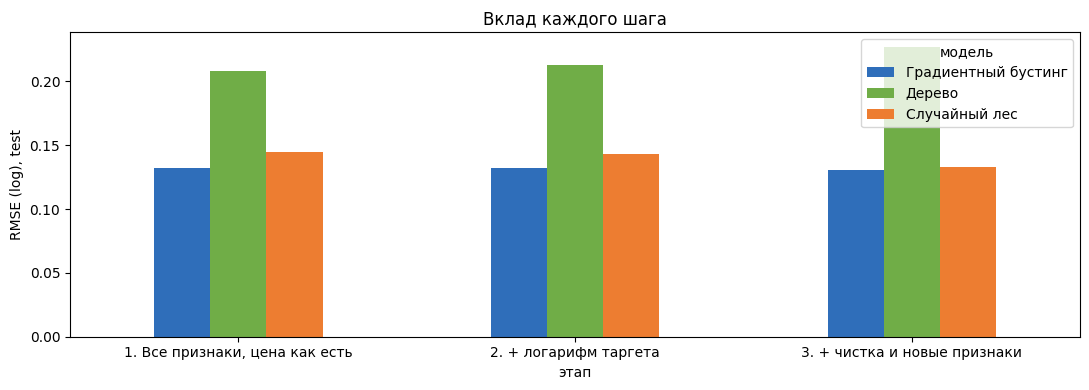

In [ ]:
ax = steps.pivot(index='этап', columns='модель', values='test').plot.bar(
    color=['#2F6EBA', '#70AD47', '#ED7D31'], rot=0, figsize=(11, 4))
ax.set_ylabel('RMSE (log), test'); ax.set_title('Вклад каждого шага')
plt.tight_layout()

### 3.3. Подбор гиперпараметров по train

In [ ]:
grids = {
    'Случайный лес': (
        RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
        {'regressor__model__max_features': [0.2, 0.33, 0.5],
         'regressor__model__min_samples_leaf': [1, 2, 4]},
    ),
    'Градиентный бустинг': (
        GradientBoostingRegressor(random_state=RANDOM_STATE, subsample=0.8, max_features='sqrt'),
        {'regressor__model__n_estimators': [1000, 2000],
         'regressor__model__learning_rate': [0.02, 0.05],
         'regressor__model__max_depth': [3, 4]},
    ),
}

def neg_log_rmse(estimator, X, y):
    # GridSearchCV максимизирует метрику, поэтому берём её со знаком минус
    return -score(y, estimator.predict(X))


best_sklearn = {}
for name, (est, grid) in grids.items():
    search = GridSearchCV(make_model(est, num_fe, cat_fe, True), grid, cv=5,
                          scoring=neg_log_rmse, n_jobs=-1)
    search.fit(X_train_fe, y_train_clean)
    best_sklearn[name] = search.best_estimator_
    print(f'{name}: CV = {-search.best_score_:.4f}, test = {score(y_test, search.predict(X_test_fe)):.4f}')
    print('   ', {k.split('__')[-1]: v for k, v in search.best_params_.items()})

Случайный лес: CV = 0.1303, test = 0.1337
    {'max_features': 0.2, 'min_samples_leaf': 1}
Градиентный бустинг: CV = 0.1135, test = 0.1194
    {'learning_rate': 0.02, 'max_depth': 4, 'n_estimators': 2000}


# 4. CatBoost

Сначала — на исходных данных без всякой подготовки (только заполняем пропуски в категориальных признаках), затем — с нашими признаками.

In [ ]:
!pip install catboost   # если библиотеки нет
from catboost import CatBoostRegressor


def fit_catboost(Xtr, ytr, cat, label):
    X_a, X_v, y_a, y_v = train_test_split(Xtr, ytr, test_size=0.2, random_state=RANDOM_STATE)
    model = CatBoostRegressor(iterations=5000, learning_rate=0.03, depth=6,
                              loss_function='RMSE', random_seed=RANDOM_STATE, verbose=0)
    model.fit(X_a, np.log1p(y_a), cat_features=cat,
              eval_set=(X_v, np.log1p(y_v)), early_stopping_rounds=300, use_best_model=True)
    print(f'{label}: лучшая итерация {model.get_best_iteration()}')
    return model


def cat_ready(X, cat):
    X = X.copy()
    # CatBoost нужны строки без пропусков; тип object надёжнее нового строкового типа pandas
    X[cat] = X[cat].astype(object).fillna('Missing').astype(str).astype(object)
    return X

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 43.5 MB/s  0:00:02


In [ ]:
cb_raw = fit_catboost(cat_ready(X_train, cat_cols), y_train, cat_cols, 'CatBoost, исходные данные')
pred_raw = np.expm1(cb_raw.predict(cat_ready(X_test, cat_cols)))
print('test:', round(score(y_test, pred_raw), 4))

CatBoost, исходные данные: лучшая итерация 1714
test: 0.1248


In [ ]:
cb_fe = fit_catboost(cat_ready(X_train_fe, cat_fe), y_train_clean, cat_fe, 'CatBoost, чистка + FE')
pred_fe = np.expm1(cb_fe.predict(cat_ready(X_test_fe, cat_fe)))
print('test:', round(score(y_test, pred_fe), 4))

CatBoost, чистка + FE: лучшая итерация 2506
test: 0.12


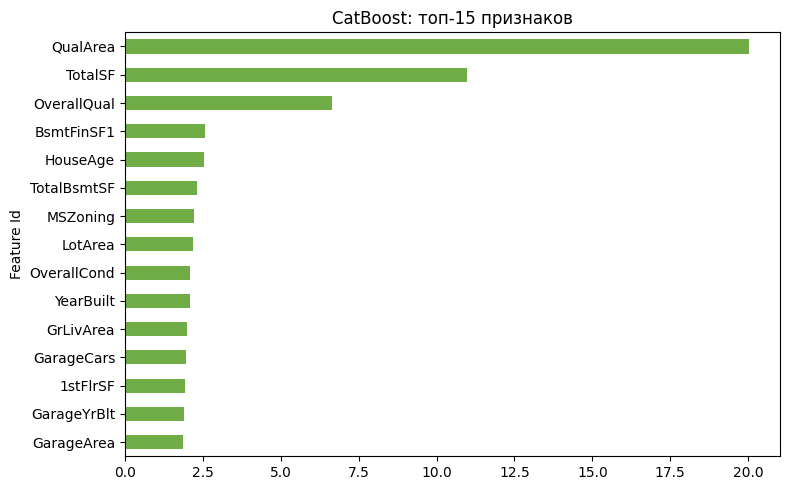

In [ ]:
imp = cb_fe.get_feature_importance(prettified=True).head(15)
ax = imp.set_index('Feature Id')['Importances'].sort_values().plot.barh(color='#70AD47', figsize=(8, 5))
ax.set_title('CatBoost: топ-15 признаков')
plt.tight_layout()

# 5. Итог

In [ ]:
base = Pipeline([('imp', SimpleImputer(strategy='median')),
                 ('model', RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1))])
base.fit(X_train[num_cols], y_train)

summary = {'RF, базовое решение (числовые признаки)': score(y_test, base.predict(X_test[num_cols]))}
first_stage = steps[steps['этап'].str.startswith('1')].set_index('модель')['test']
for n in estimators:
    summary[f'{n}, по умолчанию (все признаки)'] = first_stage[n]
for n, m in best_sklearn.items():
    summary[f'{n}, лог + FE + подбор'] = score(y_test, m.predict(X_test_fe))
try:
    summary['CatBoost, исходные данные'] = score(y_test, pred_raw)
    summary['CatBoost, чистка + FE'] = score(y_test, pred_fe)
except NameError:
    pass
pd.Series(summary, name='RMSE (log), test').round(4).sort_values().to_frame()

,"RMSE (log), test"
"Градиентный бустинг, лог + FE + подбор",0.1194
"CatBoost, чистка + FE",0.1200
"CatBoost, исходные данные",0.1248
"Градиентный бустинг, по умолчанию (все признаки)",0.1324
"Случайный лес, лог + FE + подбор",0.1337
"Случайный лес, по умолчанию (все признаки)",0.1445
"RF, базовое решение (числовые признаки)",0.1474
"Дерево, по умолчанию (все признаки)",0.2078


### Выводы для обсуждения

- **Логарифм таргета** — самый дешёвый и почти всегда полезный шаг для цен.
- **Чистка и признаки** сильнее всего помогают одиночному дереву и бустингу: суммарная площадь и `OverallQual × GrLivArea` сразу попадают в топ важности.
- **Подбор гиперпараметров** для бустинга (больше деревьев, меньше шаг, подвыборки) даёт заметный выигрыш, для леса — небольшой.
- **CatBoost на сырых данных** обычно сразу показывает качество уровня настроенного sklearn-бустинга: сам кодирует категории, сам обрабатывает пропуски в числовых признаках. Наши признаки помогают ему меньше, чем sklearn-моделям, но всё ещё помогают.
- На маленьком датасете (≈1100 объектов в train) разница между моделями в третьем знаке может быть шумом: стоит смотреть и на кросс-валидацию, а не только на один test.